# Step 3: The time split (option A)

**Goal:** decide which rows describe a customer (**features**) and which rows are the future we predict (**target**), without leaking the future into the features.

**Option A:** 12-month feature window, 6-month target window, two snapshots whose target windows don't overlap.

| Snapshot | Cutoff | Feature window | Target window |
|---|---|---|---|
| train | 2010-12-01 | 2009-12-01 .. 2010-11-30 | 2010-12-01 .. 2011-05-31 |
| test | 2011-06-01 | 2010-06-01 .. 2011-05-31 | 2011-06-01 .. 2011-11-30 |

Rules:
- Windows are half-open: the cutoff day belongs to the **target**, never to the features.
- A customer is anyone with a real **purchase** in the feature window. New customers in the target window are excluded.
- **Target** = net money kept (from the ledger) in the target window, **floored at 0** (decision from step 5: refunds of earlier purchases can push the net below zero, but a customer is never worth less than nothing). A customer who bought nothing gets **0** and stays in. Nobody is clipped from above. The unfloored value is kept as `target_net`.

The logic is in `src/step3_split.py`.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from step3_split import (load_ledger, make_snapshot, describe,
                         TRAIN_CUTOFF, TEST_CUTOFF)

pd.set_option("display.width", 160)
ledger = load_ledger()
ledger["InvoiceDate"].agg(["min", "max"])

min   2009-12-01 07:45:00
max   2011-12-09 12:50:00
Name: InvoiceDate, dtype: datetime64[us]

## 1. The two windows on a timeline

Monthly net revenue, with the four windows overlaid. Note the Christmas peak (Nov-Dec): the train target window *starts* at the peak, the test target window *ends* just before it.

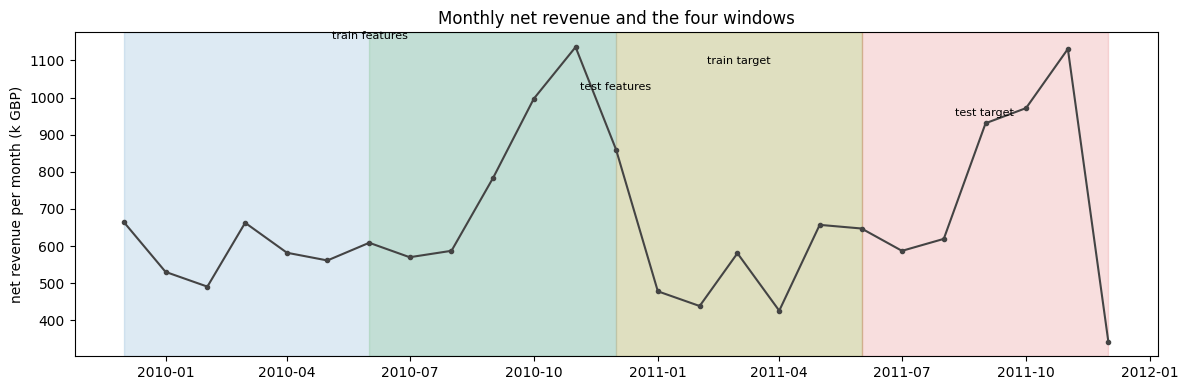

In [2]:
monthly = ledger.set_index("InvoiceDate")["TotalPrice"].resample("MS").sum() / 1e3
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(monthly.index, monthly.values, color="#444", marker="o", ms=3)

def span(a, b, color, label, y):
    ax.axvspan(a, b, color=color, alpha=0.15)
    ax.text(a + (b - a) / 2, y, label, ha="center", fontsize=8)

top = monthly.max() * 1.02
span(TRAIN_CUTOFF - pd.DateOffset(months=12), TRAIN_CUTOFF, "tab:blue", "train features", top)
span(TRAIN_CUTOFF, TRAIN_CUTOFF + pd.DateOffset(months=6), "tab:orange", "train target", top * 0.94)
span(TEST_CUTOFF - pd.DateOffset(months=12), TEST_CUTOFF, "tab:green", "test features", top * 0.88)
span(TEST_CUTOFF, TEST_CUTOFF + pd.DateOffset(months=6), "tab:red", "test target", top * 0.82)
ax.set_ylabel("net revenue per month (k GBP)")
ax.set_title("Monthly net revenue and the four windows")
plt.tight_layout()

## 2. Build both snapshots

In [3]:
train = make_snapshot(ledger, TRAIN_CUTOFF)
test = make_snapshot(ledger, TEST_CUTOFF)
describe("TRAIN", train)
describe("TEST", test)


=== TRAIN snapshot ===
features : 2009-12-01 -> 2010-11-30   (actual last row: 2010-11-30 19:35:00)
target   : 2010-12-01 -> 2011-05-31
customers (bought in feature window): 4,242
zero target : 2,203  (51.9%)
floored at 0: 51  (net negative: refunds exceeded purchases in the target window)
positive    : 2,039
target mean 714 | median 0 | 90th pct 1,551 | max 110,668

=== TEST snapshot ===
features : 2010-06-01 -> 2011-05-31   (actual last row: 2011-05-31 15:41:00)
target   : 2011-06-01 -> 2011-11-30
customers (bought in feature window): 4,326
zero target : 1,865  (43.1%)
floored at 0: 28  (net negative: refunds exceeded purchases in the target window)
positive    : 2,461
target mean 958 | median 176 | 90th pct 1,905 | max 183,530


### What to notice
- **Train has more zero-spenders (51.9%) than test (43.1%) after flooring.** The two target periods behave differently, as expected with seasonality. A model trained on one is judged on a somewhat different world.
- **51 train and 28 test customers had a negative net** (refunds exceeded purchases in the window). These are the timing cases flagged in step 2; they are now floored at 0.
- **The median train target is 0**, so more than half of customers buy nothing in the next 6 months. That matters for the choice of model later.

## 3. Leakage check

`make_snapshot` asserts that features end before the cutoff. Verify it ourselves, and verify the target windows don't overlap.

In [4]:
for name, s in [("train", train), ("test", test)]:
    last = s.feature_rows["InvoiceDate"].max()
    print(f"{name}: last feature row {last}  < cutoff {s.cutoff}?  {last < s.cutoff}")
print("train target end <= test cutoff (no overlap)?", train.target_end <= test.cutoff)

train: last feature row 2010-11-30 19:35:00  < cutoff 2010-12-01 00:00:00?  True
test: last feature row 2011-05-31 15:41:00  < cutoff 2011-06-01 00:00:00?  True
train target end <= test cutoff (no overlap)? True


## 4. The target distribution

Most customers sit at or near zero, and a few are very large. A `log1p` view makes both visible.

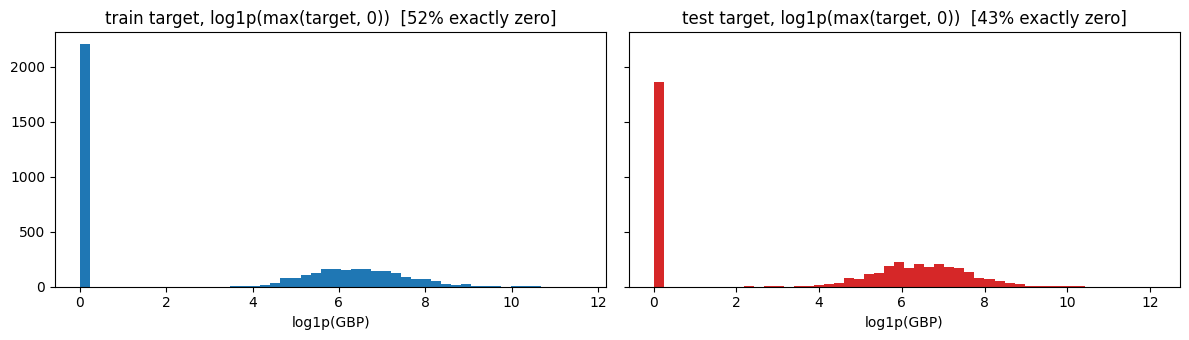

In [5]:
import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, (name, s) in zip(axes, [("train", train), ("test", test)]):
    t = s.target
    ax.hist(np.log1p(t.clip(lower=0)), bins=50, color="tab:blue" if name == "train" else "tab:red")
    ax.set_title(f"{name} target, log1p(max(target, 0))  [{(t == 0).mean():.0%} exactly zero]")
    ax.set_xlabel("log1p(GBP)")
plt.tight_layout()

In [6]:
print("Largest targets (net GBP in the target window):")
display(pd.concat({"train": train.target.nlargest(5).reset_index(drop=True),
                   "test": test.target.nlargest(5).reset_index(drop=True)}, axis=1).round(0))

for name, s in [("train", train), ("test", test)]:
    t = s.target.sort_values(ascending=False)
    print(f"{name}: top 10 customers hold {t.head(10).sum() / t.sum():.0%} of all target money; "
          f"top 1% ({int(len(t) * 0.01)} customers) hold {t.head(int(len(t) * 0.01)).sum() / t.sum():.0%}")

Largest targets (net GBP in the target window):


,train,test
0,110668.0,183530.0
1,92477.0,157405.0
2,57763.0,131500.0
3,50290.0,91957.0
4,41989.0,73435.0


train: top 10 customers hold 18% of all target money; top 1% (42 customers) hold 33%
test: top 10 customers hold 21% of all target money; top 1% (43 customers) hold 35%


## 5. The two snapshots share customers

The test is out-of-time, but it is **not** a test on brand-new customers.

In [7]:
both = train.target.index.intersection(test.target.index)
print(f"customers in both snapshots: {len(both):,}  ({len(both) / len(test.target):.0%} of test customers)")
print(f"unused tail of the data (after test target ends {test.target_end.date()}): "
      f"{(ledger['InvoiceDate'] >= test.target_end).sum():,} rows")

customers in both snapshots: 3,658  (85% of test customers)
unused tail of the data (after test target ends 2011-12-01): 17,646 rows


## What we learned

- Train: 4,242 customers, 51.9% zero target (after flooring). Test: 4,326 customers, 43.1% zero target.
- Targets don't overlap (train ends 2011-06-01, test starts 2011-06-01) and features end before each cutoff.
- The test target window is exactly 6 months; the last 8 days of data are unused.
- About 85% of test customers also appear in the train snapshot.
- The target is heavily skewed: many zeros and a few very large values. Step 5 looks at this more closely.

**Next (step 4):** build RFM features from `snapshot.feature_rows`, starting with Recency, Frequency and Monetary.